In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
input_file = "UPI_Statistics_2016_2026_Year.csv"

output_dir = Path("output")
chart_dir = output_dir / "charts"

output_dir.mkdir(exist_ok=True)
chart_dir.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")


In [3]:
df=pd.read_csv(input_file)
print("shape:",df.shape)
print(df.head())
print(df.columns.tolist())
print(df.dtypes)

shape: (126, 7)
   Year  Month_Number Month_Name  Month_Date  No. of Banks live on UPI  \
0  2016             4      April  01-04-2016                        21   
1  2016             5        May  01-05-2016                        21   
2  2016             6       June  01-06-2016                        21   
3  2016             7       July  01-07-2016                        21   
4  2016             8     August  01-08-2016                        21   

   Volume (In Mn.)  Value (In Cr.)  
0             0.00            0.00  
1             0.00            0.00  
2             0.00            0.00  
3             0.09            0.38  
4             0.09            3.09  
['Year', 'Month_Number', 'Month_Name', 'Month_Date', 'No. of Banks live on UPI', 'Volume (In Mn.)', 'Value (In Cr.)']
Year                          int64
Month_Number                  int64
Month_Name                   object
Month_Date                   object
No. of Banks live on UPI      int64
Volume (In Mn.)    

In [4]:
df.columns=df.columns.str.strip()
df["Month_Date"]=pd.to_datetime(df["Month_Date"],errors="coerce")
cols=["No. of Banks live on UPI", "Volume (In Mn.)", "Value (In Cr.)"]
df[cols]=df[cols].apply(pd.to_numeric, errors="coerce")

In [54]:
df["Year"]=df["Month_Date"].dt.year
df["Month_Number"]=df["Month_Date"].dt.month
df["Month_Name"]=df["Month_Date"].dt.month_name()

In [6]:
missing_report=df.isnull().sum().rename("Missing_Count").to_frame()
missing_report

,Missing_Count
Year,0
Month_Number,0
Month_Name,0
Month_Date,0
No. of Banks live on UPI,0
Volume (In Mn.),0
Value (In Cr.),0


In [7]:
print("Duplicate rows:",df.duplicated().sum())
df=df.drop_duplicates()
df=df.dropna(subset=["Month_Date"])
df["Year"]=df["Month_Date"].dt.year
df["Month"]=df["Month_Date"].dt.month_name()
df.sort_values("Month_Date",inplace=True)
df.reset_index(drop=True,inplace=True)

Duplicate rows: 0


In [8]:
duplicate_months=df[df.duplicated(subset=["Month_Date"], keep=False)]
print("Duplicate month records:",duplicate_months)

Duplicate month records: Empty DataFrame
Columns: [Year, Month_Number, Month_Name, Month_Date, No. of Banks live on UPI, Volume (In Mn.), Value (In Cr.), Month]
Index: []


In [9]:
df["MoM_Volume_Growth_Pct"]=df["Volume (In Mn.)"].pct_change()*100
df["YoY_Volume_Growth_Pct"]=df["Volume (In Mn.)"].pct_change(12)*100
df["MoM_Value_Growth_Pct"]=df["Value (In Cr.)"].pct_change()*100
df["YoY_Value_Growth_Pct"]=df["Value (In Cr.)"].pct_change(12)*100

growth_cols=["MoM_Volume_Growth_Pct","YoY_Volume_Growth_Pct","MoM_Value_Growth_Pct","YoY_Value_Growth_Pct"]
df[growth_cols]=df[growth_cols].replace([np.inf,-np.inf],np.nan)

In [10]:
print("\n========== NUMERICAL SUMMARY ==========")
print(df[cols].describe().round(2))
print("\n========== YEARLY ANALYSIS ==========")
yearly=df.groupby("Year").agg(
    Total_Volume_Mn=("Volume (In Mn.)","sum"),
    Total_Value_Cr=("Value (In Cr.)","sum"),
    Average_Volume_Mn=("Volume (In Mn.)","mean"),
    Average_Value_Cr=("Value (In Cr.)","mean"),
    Latest_Bank_Count=("No. of Banks live on UPI", "last"),
    Monthly_Records=("Month_Date","count")
).reset_index()
print(yearly.round(2))


========== NUMERICAL SUMMARY ==========
       No. of Banks live on UPI  Volume (In Mn.)  Value (In Cr.)
count                    126.00           126.00          126.00
mean                     317.76          6904.81       989967.15
std                      238.93          7679.47      1005486.45
min                       21.00             0.00            0.00
25%                      128.25           548.75        87322.86
50%                      232.00          3027.66       576827.16
75%                      557.50         12177.93      1837780.32
max                      756.00         24508.96      2990424.21

========== YEARLY ANALYSIS ==========
    Year  Total_Volume_Mn  Total_Value_Cr  Average_Volume_Mn  \
0   2016             2.65          893.07               0.29   
1   2017           429.15        57020.87              35.76   
2   2018          3746.32       585710.45             312.19   
3   2019         10787.54      1836638.18             898.96   
4   2020       

In [11]:
yearly["YoY_Volume_Growth_Pct"]=(yearly["Total_Volume_Mn"].pct_change(fill_method=None)*100)
print(yearly["YoY_Volume_Growth_Pct"])
yearly["Value_YoY_Growth_Pct"]=(yearly["Total_Value_Cr"].pct_change(fill_method=None)*100)
print(yearly["Value_YoY_Growth_Pct"])

0              NaN
1     16094.339623
2       772.962834
3       187.950309
4        75.024983
5       105.205104
6        91.109408
7        58.878947
8        46.384235
9        32.561691
10      -10.093939
Name: YoY_Volume_Growth_Pct, dtype: float64
0             NaN
1     6284.815300
2      927.186099
3      213.574426
4       84.453572
5      111.328963
6       75.926457
7       45.237651
8       34.930285
9       21.441152
10     -12.715044
Name: Value_YoY_Growth_Pct, dtype: float64


In [55]:
monthly_pattern = df.groupby("Month_Number").agg(
    Average_Volume=("Volume (In Mn.)", "mean"),
    Average_Value=("Value (In Cr.)", "mean")
).reset_index()

monthly_pattern["Month_Name"] = (
    pd.to_datetime(
        monthly_pattern["Month_Number"],
        format="%m"
    ).dt.month_name()
)

print(monthly_pattern)

   Month_Number  Average_Volume  Average_Value Month_Name
0             1      6904.80754  989967.151746    January


In [20]:
peak_volume=df.loc[df["Volume (In Mn.)"].idxmax()]
print("Peak Transaction Volume:")
print(peak_volume[["Month_Date","Volume (In Mn.)"]])

peak_value=df.loc[df["Value (In Cr.)"].idxmax()]
print("\nPeak Transaction Value:")
print(peak_value[["Month_Date","Value (In Cr.)"]])

Peak Transaction Volume:
Month_Date         2026-01-08 00:00:00
Volume (In Mn.)               24508.96
Name: 124, dtype: object

Peak Transaction Value:
Month_Date        2026-01-05 00:00:00
Value (In Cr.)             2990424.21
Name: 121, dtype: object


In [25]:
correlation_cols=["No. of Banks live on UPI","Volume (In Mn.)","Value (In Cr.)"]
correlation=df[correlation_cols].corr()
print("\n========== CORRELATION MATRIX ==========")
print(correlation.round(3))


========== CORRELATION MATRIX ==========
                          No. of Banks live on UPI  Volume (In Mn.)  \
No. of Banks live on UPI                     1.000            0.979   
Volume (In Mn.)                              0.979            1.000   
Value (In Cr.)                               0.992            0.994   

                          Value (In Cr.)  
No. of Banks live on UPI           0.992  
Volume (In Mn.)                    0.994  
Value (In Cr.)                     1.000  


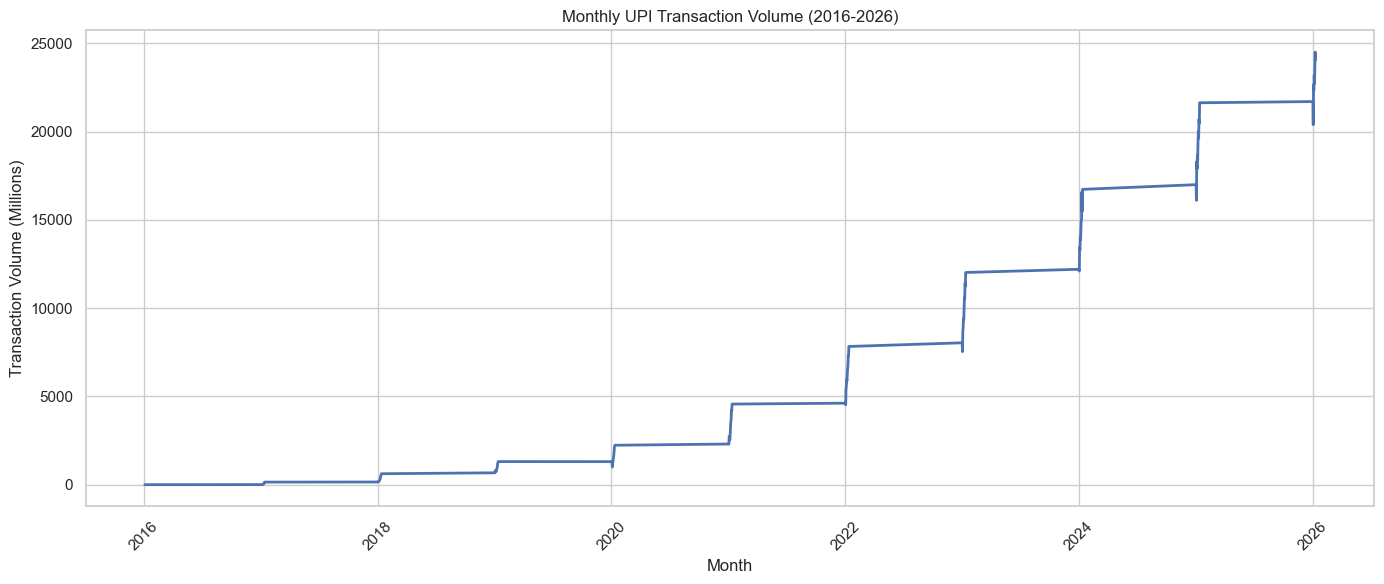

In [31]:
plt.figure(figsize=(14,6))
sns.lineplot(data=df,x="Month_Date",y="Volume (In Mn.)",linewidth=2)
plt.title("Monthly UPI Transaction Volume (2016-2026)")
plt.xlabel("Month")
plt.ylabel("Transaction Volume (Millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

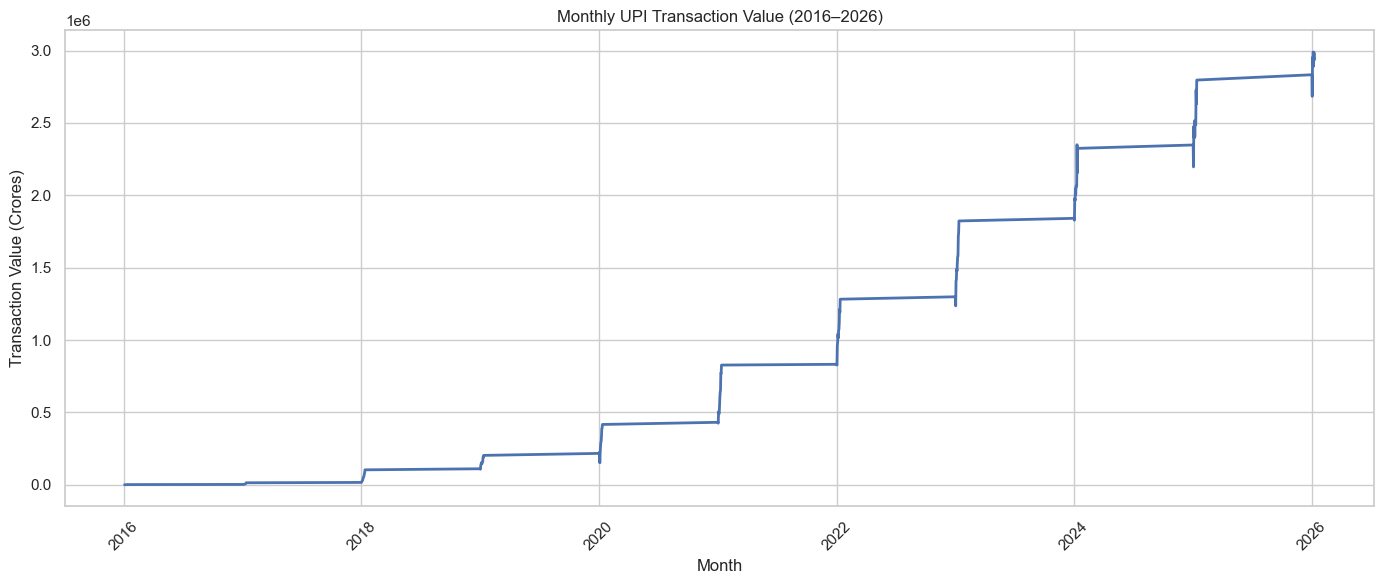

In [ ]:
plt.figure(figsize=(14,6))
sns.lineplot(data=df,x="Month_Date",y="Value (In Cr.)",linewidth=2)
plt.title("Monthly UPI Transaction Value (2016-2026)")
plt.xlabel("Month")
plt.ylabel("Transaction Value (Crores)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

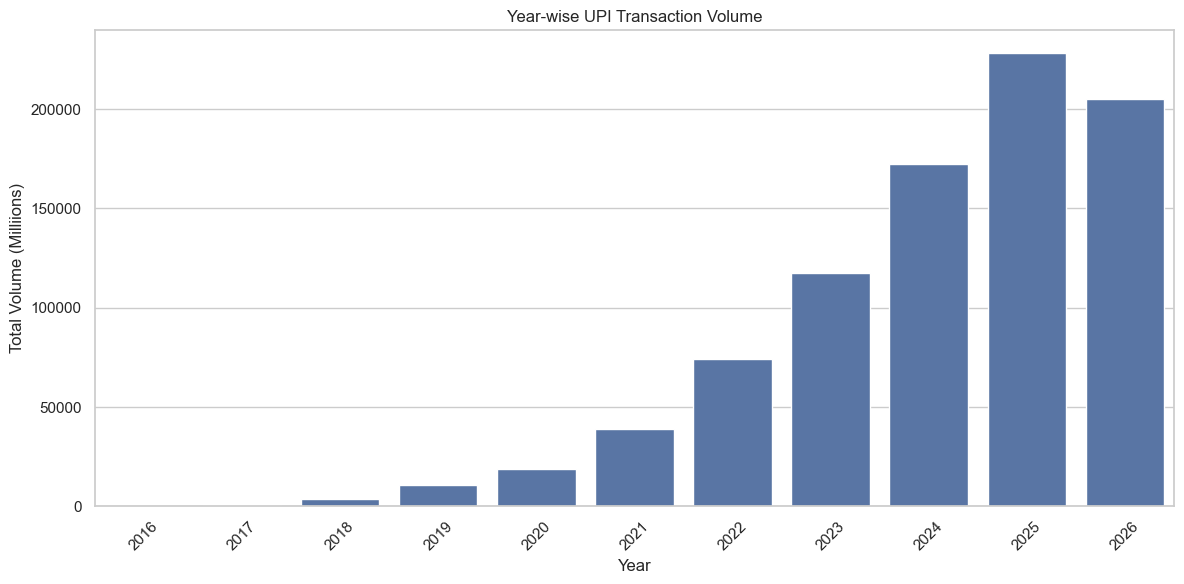

In [36]:
plt.figure(figsize=(12,6))
sns.barplot(data=yearly,x="Year",y="Total_Volume_Mn")
plt.title("Year-wise UPI Transaction Volume")
plt.xlabel("Year")
plt.ylabel("Total Volume (Milliions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

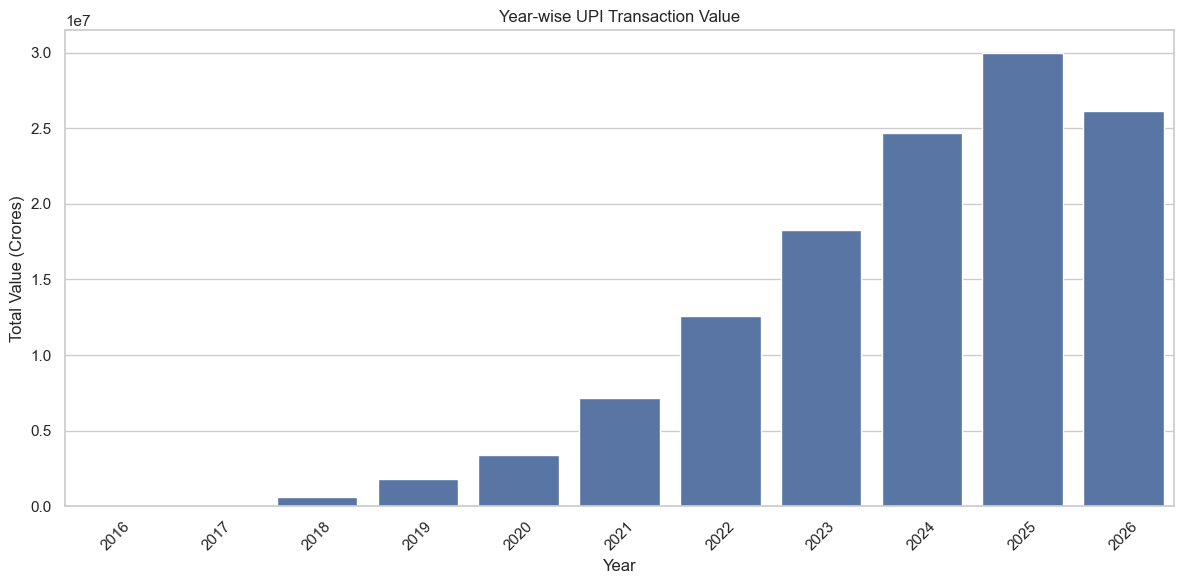

In [38]:
plt.figure(figsize=(12,6))
sns.barplot(data=yearly,x="Year",y="Total_Value_Cr")
plt.title("Year-wise UPI Transaction Value")
plt.xlabel("Year")
plt.ylabel("Total Value (Crores)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

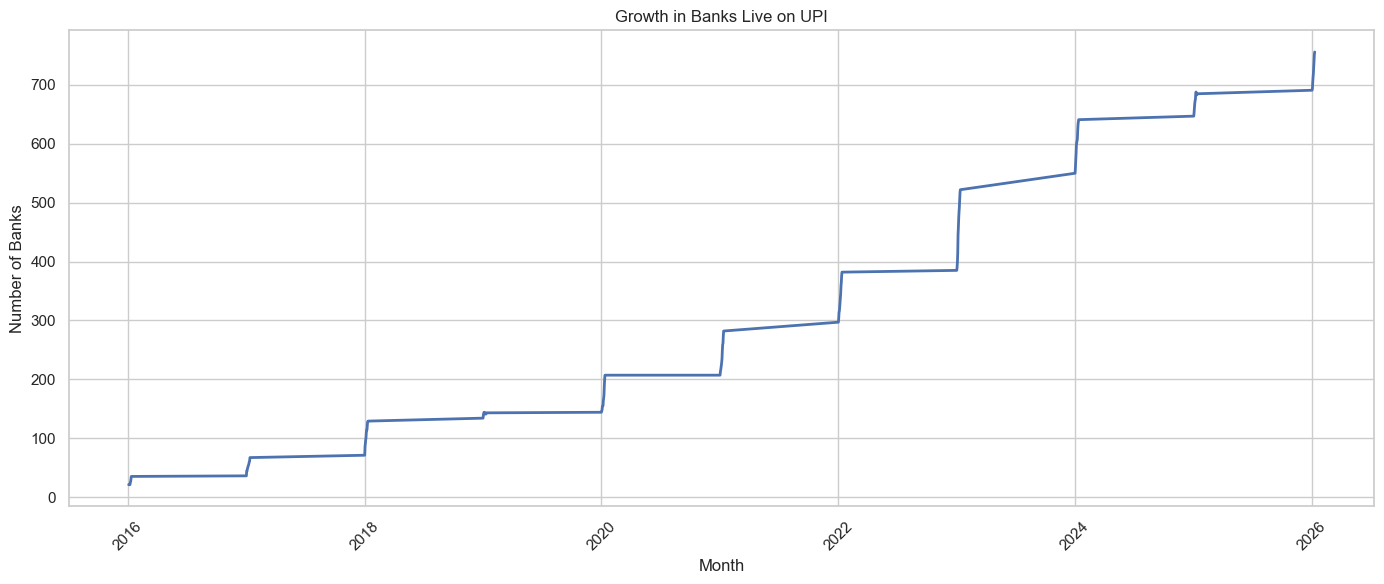

In [39]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=df,x="Month_Date",y="No. of Banks live on UPI",linewidth=2)
plt.title("Growth in Banks Live on UPI")
plt.xlabel("Month")
plt.ylabel("Number of Banks")
plt.xticks(rotation=45)
plt.tight_layout()

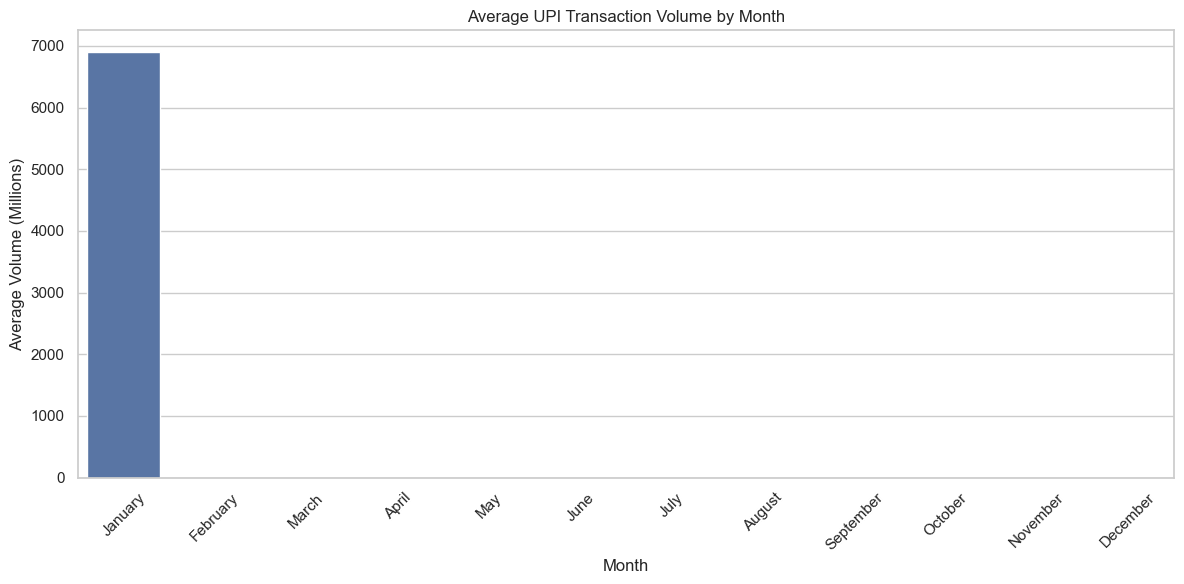

In [57]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=monthly_pattern,
    x="Month_Name",
    y="Average_Volume",
    order=[
        "January", "February", "March",
        "April", "May", "June",
        "July", "August", "September",
        "October", "November", "December"
    ]
)
plt.title("Average UPI Transaction Volume by Month")
plt.xlabel("Month")
plt.ylabel("Average Volume (Millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

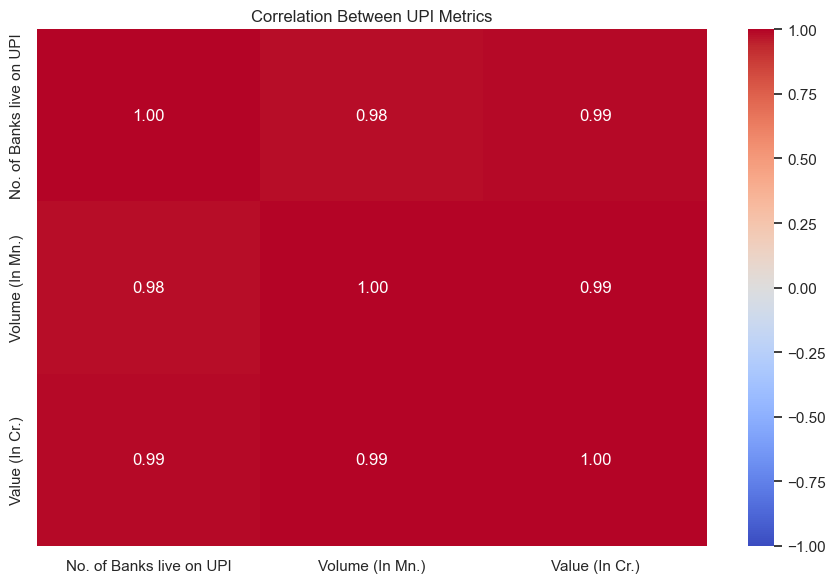

In [ ]:
plt.figure(figsize=(9, 6))
sns.heatmap(correlation,annot=True,fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1)
plt.title("Correlation Between UPI Metrics")
plt.tight_layout()
plt.show()

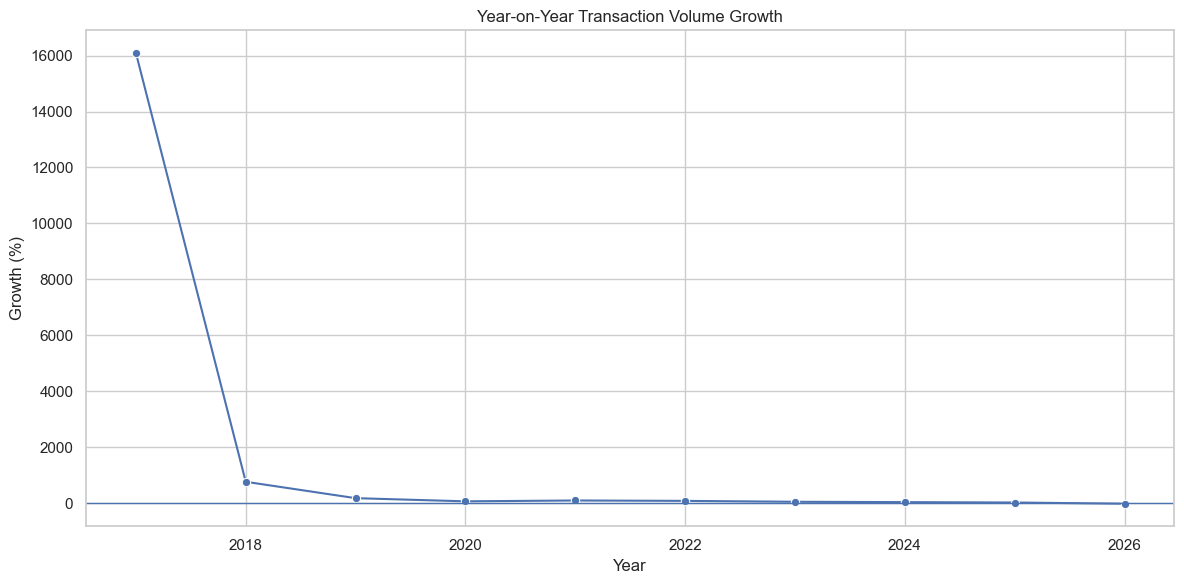

In [51]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=yearly,x="Year",y="YoY_Volume_Growth_Pct",marker="o")
plt.axhline(0, linewidth=1)
plt.title("Year-on-Year Transaction Volume Growth")
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.tight_layout()
plt.show()

In [53]:
df.to_csv(output_dir / "UPI_Statistics_Cleaned.csv",index=False)
print("\n========== PROJECT COMPLETED ==========")
print("Final dataset shape:", df.shape)
print("Output folder:", output_dir.resolve())
print("Charts folder:", chart_dir.resolve())
print("Cleaned dataset exported successfully.")


========== PROJECT COMPLETED ==========
Final dataset shape: (126, 12)
Output folder: C:\Users\dsudh\OneDrive\Desktop\UPI_Statistics\output
Charts folder: C:\Users\dsudh\OneDrive\Desktop\UPI_Statistics\output\charts
Cleaned dataset exported successfully.
